In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows: 20640
Number of Columns: 9

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
print(housing.DESCR[:3000])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [6]:
display(df.describe())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
print("Missing Values:")
display(df.isnull().sum())

Missing Values:


MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [9]:
df_clean = df.copy()

# Remove exact duplicate records if present
df_clean = df_clean.drop_duplicates()

# Handle missing numerical values using median
for col in df_clean.select_dtypes(include=np.number).columns:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Data cleaning completed!")
print("Final Shape:", df_clean.shape)
print("Remaining Missing Values:", df_clean.isnull().sum().sum())
print("Remaining Duplicates:", df_clean.duplicated().sum())

Data cleaning completed!
Final Shape: (20640, 9)
Remaining Missing Values: 0
Remaining Duplicates: 0


In [10]:
X = df_clean[["MedInc"]]
y = df_clean["MedHouseVal"]

print("Input Feature (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature (X):


,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462



Target Variable (y):


0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


Input Shape: (20640, 1)
Target Shape: (20640,)


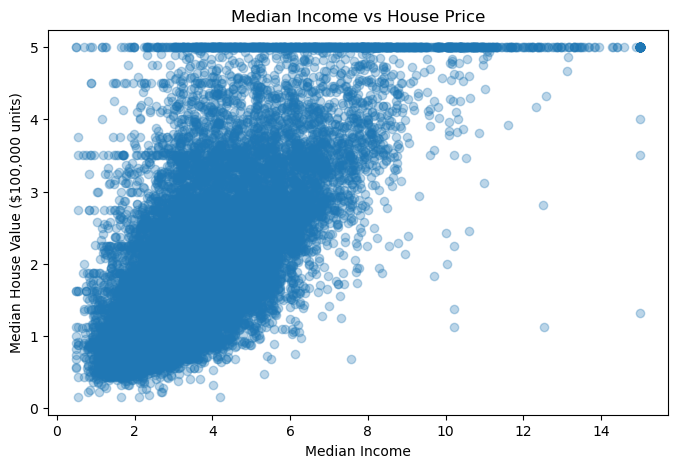

In [11]:
plt.figure(figsize=(8, 5))

plt.scatter(X["MedInc"], y, alpha=0.3)

plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Median House Value ($100,000 units)")

plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Records: 16512
Testing Records: 4128
Training Shape: (16512, 1)
Testing Shape: (4128, 1)


In [13]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [14]:
coefficient = model.coef_[0]
intercept = model.intercept_

print("Coefficient (Slope):", coefficient)
print("Intercept:", intercept)

Coefficient (Slope): 0.41933849393812705
Intercept: 0.4445972916907881


In [15]:
print("Linear Regression Equation:")

print(f"y = {intercept:.4f} + ({coefficient:.4f} * X)")

Linear Regression Equation:
y = 0.4446 + (0.4193 * X)


In [16]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [17]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(comparison.head(10))

,Actual Price,Predicted Price
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


In [18]:
comparison["Difference"] = (
    comparison["Actual Price"] -
    comparison["Predicted Price"]
)

display(comparison.head(10))

,Actual Price,Predicted Price,Difference
0,0.47700,1.149589,-0.672589
1,0.45800,1.506069,-1.048069
2,5.00001,1.903937,3.096073
3,2.18600,2.850594,-0.664594
4,2.78000,2.006633,0.773367
5,1.58700,2.421652,-0.834652
6,1.98200,2.576472,-0.594472
7,1.57500,1.992292,-0.417292
8,3.40000,2.458932,0.941068
9,4.46600,3.846774,0.619226


In [19]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Results
------------------------
MAE: 0.629908653009376
MSE: 0.7091157771765548
RMSE: 0.8420901241414454
R2 Score: 0.45885918903846656


In [20]:
metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Value": [mae, mse, rmse, r2]
})

display(metrics)

,Metric,Value
0,MAE,0.629909
1,MSE,0.709116
2,RMSE,0.842090
3,R2 Score,0.458859


In [21]:
if r2 >= 0.75:
    print("The model shows a strong fit.")
elif r2 >= 0.50:
    print("The model shows a moderate fit.")
elif r2 >= 0:
    print("The model shows a weak fit.")
else:
    print("The model performs worse than the mean baseline.")

print("R2 Score:", round(r2, 4))
print("Average Absolute Error in dollars:", round(mae * 100000, 2))

The model shows a weak fit.
R2 Score: 0.4589
Average Absolute Error in dollars: 62990.87


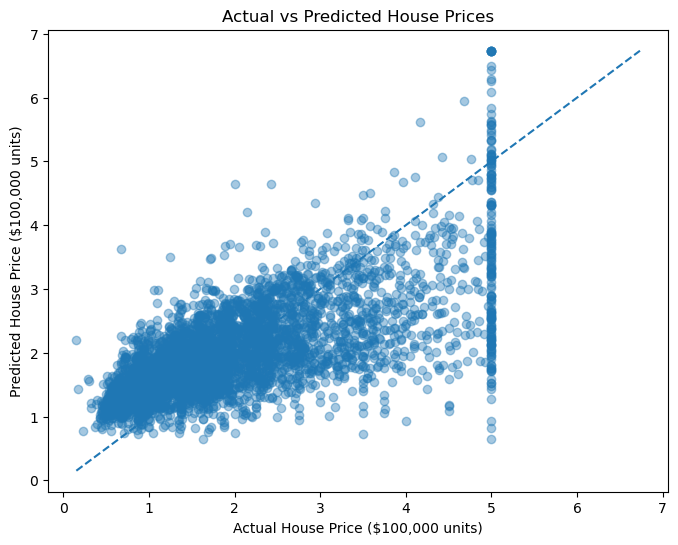

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Price ($100,000 units)")
plt.ylabel("Predicted House Price ($100,000 units)")

plt.show()

In [23]:
new_house = pd.DataFrame({
    "MedInc": [5.0]
})

predicted_price = model.predict(new_house)

print("New House Median Income:", 5.0)

print(
    "Predicted House Value:",
    round(predicted_price[0], 4),
    "($100,000 units)"
)

print(
    "Predicted Price in Dollars:",
    round(predicted_price[0] * 100000, 2)
)

New House Median Income: 5.0
Predicted House Value: 2.5413 ($100,000 units)
Predicted Price in Dollars: 254128.98


In [24]:
df_clean.to_csv(
    "California_Housing_Prepared.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!
